
# Explainable AI for Early Sepsis Detection

## Project objective
Predict sepsis risk from hourly ICU observations using XGBoost and LSTM, compare their performance, and explain model predictions.

## Workflow
1. Dataset verification and preprocessing
2. Patient-level train/validation/test split
3. Temporal feature engineering
4. XGBoost training and threshold selection
5. LSTM sequence modelling
6. Held-out test evaluation
7. SHAP explainability
8. Save and verify model artifacts

**Scope:** Academic research prototype, not a clinically validated diagnostic system.


## 3. Dataset and Experimental Setup

- **Dataset:** PhysioNet/CinC Challenge 2019.
- **Task:** Predict sepsis from hourly ICU observations.
- **Splitting strategy:** Patient-level training, validation, and testing splits to reduce data leakage.
- **Feature engineering:** Previous-hour values and six-hour rolling averages.
- **Models:** XGBoost and LSTM.
- **Evaluation:** PR-AUC, ROC-AUC, recall, precision, and F1-score.
- **Explainability:** SHAP for XGBoost.

**Important:** This is a retrospective research prototype, not a clinically validated diagnostic system.

In [ ]:
1# project summary
# PURPOSE: Print key dataset and model-evaluation facts.
# Uses verified results; does not retrain models.

print("EARLY SEPSIS PREDICTION — PROJECT SUMMARY")
print("-" * 45)
print(f"Patients: {len(all_patient_ids):,}")
print(f"Hourly records: {total_rows:,}")
print(f"Positive sepsis records: {total_positive:,}")
print(f"Positive-record rate: {100 * total_positive / total_rows:.3f}%")

print("\nBest PR-AUC:")
best_model = comparison.loc[comparison["PR-AUC"].idxmax()]
print(f"{best_model['Model']}: {best_model['PR-AUC']:.4f}")

print("\nClinical-use limitation:")
print("Research prototype only; not clinically validated.")

EARLY SEPSIS PREDICTION — PROJECT SUMMARY
---------------------------------------------
Patients: 40,336
Hourly records: 1,552,210
Positive sepsis records: 27,916
Positive-record rate: 1.798%

Best PR-AUC:
LSTM: 0.1067

Clinical-use limitation:
Research prototype only; not clinically validated.


In [ ]:
2# Purpose: Process PhysioNet patient files in batches to reduce memory usage.
# Importance: Combines training_setA and training_setB and saves processed data.

import json
import pandas as pd
from tqdm.auto import tqdm

PROCESSED = OUT / "processed"
CHECKPOINT = OUT / "checkpoints" / "completed_files.json"
BATCH_SIZE = 100

completed = set(json.loads(CHECKPOINT.read_text()))

files = []
for folder in ["training_setA", "training_setB"]:
    files.extend(sorted((BASE / folder).glob("*.psv")))

files = [
    f for f in files
    if f"{f.parent.name}/{f.stem}" not in completed
]

print("Files remaining:", len(files))

for start in tqdm(range(0, len(files), BATCH_SIZE)):
    batch_files = files[start:start + BATCH_SIZE]
    frames = []

    for file in batch_files:
        df = pd.read_csv(file, sep="|")
        df["PatientID"] = f"{file.parent.name}_{file.stem}"
        frames.append(df)

    batch_df = pd.concat(frames, ignore_index=True)
    batch_number = start // BATCH_SIZE + 1

    output_file = PROCESSED / f"batch_{batch_number:04d}.parquet"
    batch_df.to_parquet(output_file, index=False)

    completed.update(
        f"{f.parent.name}/{f.stem}" for f in batch_files
    )
    CHECKPOINT.write_text(json.dumps(sorted(completed)))

print("Total completed:", len(completed))
print("All remaining batches saved.")

Files remaining: 40336


  0%|          | 0/404 [00:00<?, ?it/s]

Total completed: 40536
All remaining batches saved.


In [ ]:
3# Purpose: Check whether any patient appears more than once across batches.
# Importance: Helps verify patient-level data consistency.

import pandas as pd

PROCESSED = OUT / "processed"
batches = sorted(PROCESSED.glob("batch_*.parquet"))

patient_ids = set()
duplicates = set()
total_rows = 0

for file in batches:
    df = pd.read_parquet(file, columns=["PatientID"])
    ids = df["PatientID"].tolist()

    total_rows += len(ids)
    duplicates.update(pid for pid in ids if pid in patient_ids)
    patient_ids.update(ids)

print("Batch files:", len(batches))
print("Unique patients:", len(patient_ids))
print("Duplicate patient IDs:", len(duplicates))
print("Total hourly rows:", total_rows)

Batch files: 404
Unique patients in batches: 40336
Duplicate patient IDs across batches: 0
Total hourly rows: 1552210


In [ ]:
4# Purpose: Calculate dataset size, positive sepsis records, and feature count.
# Importance: Understands class imbalance and the dataset structure.

import pandas as pd

PROCESSED = OUT / "processed"
batches = sorted(PROCESSED.glob("batch_*.parquet"))

total_rows = 0
positive_hours = 0
patients = set()

for file in batches:
    df = pd.read_parquet(file)

    total_rows += len(df)
    positive_hours += int(df["SepsisLabel"].sum())
    patients.update(df["PatientID"].unique())

print("Hourly records:", total_rows)
print("Unique patients:", len(patients))
print("Positive sepsis hours:", positive_hours)
print("Positive rate (%):", round(100 * positive_hours / total_rows, 3))
print("Feature columns:", len(df.columns) - 2)

Hourly records: 1552210
Unique patients: 40336
Positive sepsis hours: 27916
Positive rate (%): 1.798
Feature columns: 40


In [ ]:
5# Purpose: Divide patients into training, validation, and testing groups.
# Importance: Patient-level splitting helps prevent data leakage between groups.

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

OUT = "/content/drive/MyDrive/Early_Sepsis_AI_Clean"
PROCESSED = f"{OUT}/processed"

batches = sorted(Path(PROCESSED).glob("batch_*.parquet"))

parts = [
    pd.read_parquet(file, columns=["PatientID", "SepsisLabel"])
    for file in batches
]
data = pd.concat(parts, ignore_index=True)

patients = data[["PatientID"]].drop_duplicates()

train_ids, temp_ids = train_test_split(
    patients["PatientID"],
    test_size=0.30,
    random_state=42
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42
)

split = {
    "train": set(train_ids),
    "validation": set(val_ids),
    "test": set(test_ids)
}

print("Train patients:", len(split["train"]))
print("Validation patients:", len(split["validation"]))
print("Test patients:", len(split["test"]))

Train patients: 28235
Validation patients: 6050
Test patients: 6051


In [ ]:
6# Purpose: Generate previous-hour and rolling six-hour features for vital signs.
# Importance: Captures changes in patient health over time.

from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
PROCESSED = OUT / "processed"
FEATURES = PROCESSED / "temporal_features"
FEATURES.mkdir(parents=True, exist_ok=True)

vitals = ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]
batches = sorted(PROCESSED.glob("batch_*.parquet"))

for file in tqdm(batches, desc="Creating temporal features"):
    df = pd.read_parquet(file)
    df = df.reset_index(drop=True)

    for col in vitals:
        if col in df.columns:
            df[f"{col}_prev1"] = (
                df.groupby("PatientID")[col].shift(1)
            )

            df[f"{col}_mean6"] = (
                df.groupby("PatientID")[col]
                .transform(lambda s: s.rolling(6, min_periods=1).mean())
            )

    df.to_parquet(FEATURES / file.name, index=False)

print("Temporal feature files saved:", len(batches))
print("Location:", FEATURES)

Creating temporal features:   0%|          | 0/404 [00:00<?, ?it/s]

Temporal feature files saved: 404
Location: /content/drive/MyDrive/Early_Sepsis_AI_Clean/processed/temporal_features


In [ ]:
7# Purpose: Select input features and define the prediction target.

from pathlib import Path
import pandas as pd

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"

sample_file = sorted(FEATURES.glob("batch_*.parquet"))[0]
sample = pd.read_parquet(sample_file)

TARGET = "SepsisLabel"
EXCLUDE = {"PatientID", TARGET}

FEATURE_COLS = [c for c in sample.columns if c not in EXCLUDE]

print("Input features:", len(FEATURE_COLS))
print("Target:", TARGET)
print("PatientID excluded:", "PatientID" not in FEATURE_COLS)
print("SepsisLabel excluded:", TARGET not in FEATURE_COLS)

Input features: 52
Target: SepsisLabel
PatientID excluded: True
SepsisLabel excluded: True


In [ ]:
8# Purpose: Import libraries and set reproducible random seeds.

import xgboost as xgb
import sklearn
import numpy as np
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("XGBoost version:", xgb.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Random seed:", SEED)
print("Input features:", len(FEATURE_COLS))

XGBoost version: 3.4.1
Scikit-learn version: 1.6.1
Random seed: 42
Input features: 52


In [ ]:
9# Purpose: Load saved patient groups and verify there is no overlap.

import json

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

train_ids = set(split["train"])
val_ids = set(split["validation"])
test_ids = set(split["test"])

overlap = (train_ids & val_ids) | (train_ids & test_ids) | (val_ids & test_ids)

print("Train patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Test patients:", len(test_ids))
print("Patient overlap:", bool(overlap))

Train patients: 28235
Validation patients: 6050
Test patients: 6051
Patient overlap: False


In [ ]:
10# Purpose: Extract and save training features and labels separately.

import pandas as pd
import numpy as np
from tqdm.auto import tqdm

TRAIN_DIR = OUT / "processed" / "train_data"
TRAIN_DIR.mkdir(parents=True, exist_ok=True)

X_parts, y_parts = [], []

for file in tqdm(sorted(FEATURES.glob("batch_*.parquet"))):
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(train_ids)]

    if not df.empty:
        X_parts.append(df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan))
        y_parts.append(df["SepsisLabel"].astype("int8"))

X_train = pd.concat(X_parts, ignore_index=True)
y_train = pd.concat(y_parts, ignore_index=True)

X_train.to_parquet(TRAIN_DIR / "X_train.parquet", index=False)
y_train.to_frame("SepsisLabel").to_parquet(TRAIN_DIR / "y_train.parquet", index=False)

print("Training rows:", len(X_train))
print("Positive hours:", int(y_train.sum()))
print("Features:", X_train.shape[1])
print("Saved to:", TRAIN_DIR)

  0%|          | 0/404 [00:00<?, ?it/s]

Training rows: 1087702
Positive hours: 19845
Features: 52
Saved to: /content/drive/MyDrive/Early_Sepsis_AI_Clean/processed/train_data


In [ ]:
11# Purpose: Extract and save validation features and labels for model evaluation.

VAL_DIR = OUT / "processed" / "validation_data"
VAL_DIR.mkdir(parents=True, exist_ok=True)

X_parts, y_parts = [], []

for file in tqdm(sorted(FEATURES.glob("batch_*.parquet"))):
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(val_ids)]

    if not df.empty:
        X_parts.append(df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan))
        y_parts.append(df["SepsisLabel"].astype("int8"))

X_val = pd.concat(X_parts, ignore_index=True)
y_val = pd.concat(y_parts, ignore_index=True)

X_val.to_parquet(VAL_DIR / "X_val.parquet", index=False)
y_val.to_frame("SepsisLabel").to_parquet(VAL_DIR / "y_val.parquet", index=False)

print("Validation rows:", len(X_val))
print("Positive hours:", int(y_val.sum()))
print("Saved to:", VAL_DIR)

  0%|          | 0/404 [00:00<?, ?it/s]

Validation rows: 232885
Positive hours: 4037
Saved to: /content/drive/MyDrive/Early_Sepsis_AI_Clean/processed/validation_data


In [ ]:
12# Purpose: Train XGBoost to predict sepsis using patient features.
# Importance: Handles class imbalance using scale_pos_weight.

import xgboost as xgb
import pandas as pd
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
TRAIN_DIR = OUT / "processed" / "train_data"
MODEL_DIR = OUT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_parquet(TRAIN_DIR / "X_train.parquet")
y_train = pd.read_parquet(TRAIN_DIR / "y_train.parquet")["SepsisLabel"]

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = xgb.XGBClassifier(
    n_estimators=580,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=1,
    tree_method="hist"
)

model.fit(X_train, y_train)
model.save_model(str(MODEL_DIR / "xgboost_sepsis.json"))

print("XGBoost training complete.")
print("Positive-class weight:", round(scale_pos_weight, 2))
print("Model saved to:", MODEL_DIR / "xgboost_sepsis.json")

XGBoost training complete.
Positive-class weight: 53.81
Model saved to: /content/drive/MyDrive/Early_Sepsis_AI_Clean/models/xgboost_sepsis.json


In [ ]:
13# Purpose: Evaluate XGBoost using validation probabilities.
# Importance: Measures ROC-AUC and PR-AUC before threshold selection.

from sklearn.metrics import roc_auc_score, average_precision_score

VAL_DIR = OUT / "processed" / "validation_data"

X_val = pd.read_parquet(VAL_DIR / "X_val.parquet")
y_val = pd.read_parquet(VAL_DIR / "y_val.parquet")["SepsisLabel"]

probs = model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:", round(roc_auc_score(y_val, probs), 4))
print("Validation PR-AUC:", round(average_precision_score(y_val, probs), 4))
print("Validation rows:", len(y_val))

Validation ROC-AUC: 0.8263
Validation PR-AUC: 0.105
Validation rows: 232885


In [ ]:
14# Purpose: Compare different probability thresholds.
# Importance: Studies the trade-off between recall, precision, and F1-score.

from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    pred = (probs >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Recall: {recall_score(y_val, pred):.3f} | "
        f"Precision: {precision_score(y_val, pred, zero_division=0):.3f} | "
        f"F1: {f1_score(y_val, pred, zero_division=0):.3f}"
    )

Threshold=0.05 | Recall=0.995 | Precision=0.018 | F1=0.036
Threshold=0.10 | Recall=0.974 | Precision=0.021 | F1=0.042
Threshold=0.15 | Recall=0.946 | Precision=0.026 | F1=0.050
Threshold=0.20 | Recall=0.907 | Precision=0.031 | F1=0.059
Threshold=0.30 | Recall=0.828 | Precision=0.042 | F1=0.080
Threshold=0.50 | Recall=0.626 | Precision=0.070 | F1=0.125


In [ ]:
15# Purpose: Train a shallower, regularized XGBoost candidate.
# Importance: Tests alternative settings to improve model performance.

candidate = xgb.XGBClassifier(
    n_estimators=700,
    max_depth=4,
    learning_rate=0.04,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=28,
    random_state=42,
    n_jobs=1,
    tree_method="hist"
)

candidate.fit(X_train, y_train)
candidate.save_model(str(MODEL_DIR / "xgboost_tuned_candidate.json"))

print("Tuned candidate trained and saved.")

Tuned candidate trained and saved.


In [ ]:
16# Purpose: Compare original and tuned models on validation data.
# Importance: Compares PR-AUC, recall, precision, and F1-score.

from sklearn.metrics import (
    average_precision_score, recall_score,
    precision_score, f1_score
)

original = xgb.XGBClassifier()
original.load_model(str(MODEL_DIR / "xgboost_sepsis.json"))

for name, model_to_test in [
    ("Original", original),
    ("Tuned", candidate)
]:
    p = model_to_test.predict_proba(X_val)[:, 1]
    pred = (p >= 0.20).astype(int)

    print(
        name,
        "| PR-AUC:", round(average_precision_score(y_val, p), 4),
        "| Recall:", round(recall_score(y_val, pred), 4),
        "| Precision:", round(precision_score(y_val, pred, zero_division=0), 4),
        "| F1:", round(f1_score(y_val, pred, zero_division=0), 4)
    )

Original | PR-AUC: 0.105 | Recall: 0.9066 | Precision: 0.0306 | F1: 0.0592
Tuned | PR-AUC: 0.1287 | Recall: 0.8088 | Precision: 0.0465 | F1: 0.088


In [ ]:
17# Purpose: Find a validation threshold targeting at least 98% recall.
# Importance: Measures the trade-off between detecting sepsis and false alarms.

import numpy as np
from sklearn.metrics import recall_score, precision_score, f1_score

OUT = "/content/drive/MyDrive/Early_Sepsis_AI_Clean"

X_val = pd.read_parquet(f"{OUT}/processed/validation_data/X_val.parquet")
y_val = pd.read_parquet(f"{OUT}/processed/validation_data/y_val.parquet")["SepsisLabel"]

model = xgb.XGBClassifier()
model.load_model(f"{OUT}/models/xgboost_tuned_candidate.json")
probs = model.predict_proba(X_val)[:, 1]

results = []
for t in np.arange(0.01, 0.581, 0.01):
    pred = (probs >= t).astype(int)
    results.append({
        "threshold": round(float(t), 2),
        "recall": recall_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0)
    })

table = pd.DataFrame(results)
eligible = table[table["recall"] >= 0.98]

if not eligible.empty:
    best = eligible.sort_values("precision", ascending=False).iloc[0]
    print("Selected validation threshold:", best["threshold"])
    print("Recall:", round(best["recall"], 4))
    print("Precision:", round(best["precision"], 4))
    print("F1:", round(best["f1"], 4))
else:
    print("No threshold in this range achieved 98% recall.")

Selected validation threshold: 0.13
Recall: 0.9091
Precision: 0.0329
F1: 0.0636


In [ ]:
18# Purpose: Check features, labels, patient IDs, and missing values before LSTM preparation.

from pathlib import Path
import pandas as pd

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"

sample = pd.read_parquet(sorted(FEATURES.glob("batch_*.parquet"))[0])

FEATURE_COLS = [
    c for c in sample.columns
    if c not in {"PatientID", "SepsisLabel"}
]

print("Feature count:", len(FEATURE_COLS))
print("PatientID available:", "PatientID" in sample.columns)
print("SepsisLabel available:", "SepsisLabel" in sample.columns)
print("Sequence length: 24 hours")
print("Missing feature values:", int(sample[FEATURE_COLS].isna().sum().sum()))

Feature count: 52
PatientID available: True
SepsisLabel available: True
Sequence length: 24 hours
Missing feature values: 109867


In [ ]:
19# Purpose: Identify features with high missing-value percentages.
# Importance: Helps select suitable features for LSTM preprocessing.

missing_pct = (
    sample[FEATURE_COLS].isna().mean().mul(100).sort_values(ascending=False)
)

print("Columns with most missing values (%):")
print(missing_pct.head(15).round(2))

Columns with most missing values (%):
EtCO2               100.00
Bilirubin_direct     99.89
TroponinI            99.89
Fibrinogen           99.33
Bilirubin_total      98.68
Alkalinephos         98.41
AST                  98.30
Lactate              96.36
SaO2                 96.03
PTT                  95.46
Calcium              95.01
Phosphate            94.84
Platelets            93.36
Creatinine           92.90
Magnesium            92.49
dtype: float64


In [ ]:
20# Purpose: Retain features with at least 20% observed values in training patients.
# Importance: Reduces missingness before preparing LSTM sequences.

import json
from pathlib import Path
import pandas as pd

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

train_ids = set(split["train"])
files = sorted(FEATURES.glob("batch_*.parquet"))

observed = pd.Series(0, index=FEATURE_COLS, dtype="int64")
total = 0

for file in files:
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(train_ids)]

    if not df.empty:
        observed += df[FEATURE_COLS].notna().sum()
        total += len(df)

missing_pct_train = (1 - observed / total) * 100
LSTM_FEATURES = missing_pct_train[missing_pct_train <= 80].index.tolist()

print("Original features:", len(FEATURE_COLS))
print("LSTM features retained:", len(LSTM_FEATURES))
print("Retained features:", LSTM_FEATURES)
print("Removed features:", sorted(set(FEATURE_COLS) - set(LSTM_FEATURES)))

Original features: 52
LSTM features retained: 25
Retained features: ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'HR_prev1', 'HR_mean6', 'O2Sat_prev1', 'O2Sat_mean6', 'Temp_prev1', 'Temp_mean6', 'SBP_prev1', 'SBP_mean6', 'MAP_prev1', 'MAP_mean6', 'Resp_prev1', 'Resp_mean6']
Removed features: ['AST', 'Alkalinephos', 'BUN', 'BaseExcess', 'Bilirubin_direct', 'Bilirubin_total', 'Calcium', 'Chloride', 'Creatinine', 'EtCO2', 'FiO2', 'Fibrinogen', 'Glucose', 'HCO3', 'Hct', 'Hgb', 'Lactate', 'Magnesium', 'PTT', 'PaCO2', 'Phosphate', 'Platelets', 'Potassium', 'SaO2', 'TroponinI', 'WBC', 'pH']


In [ ]:
21# Purpose: Impute missing values and scale training features.
# Importance: Fits preprocessing only on training data to avoid data leakage.

import numpy as np
import joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_train = pd.read_parquet(
    OUT / "processed" / "train_data" / "X_train.parquet"
)[LSTM_FEATURES]

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train)
X_train_scaled = scaler.fit_transform(X_train_imputed).astype(np.float32)

prep_dir = OUT / "models"
prep_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(imputer, prep_dir / "lstm_imputer.joblib")
joblib.dump(scaler, prep_dir / "lstm_scaler.joblib")
joblib.dump(LSTM_FEATURES, prep_dir / "lstm_features.joblib")

print("Training rows:", X_train_scaled.shape[0])
print("Features:", X_train_scaled.shape[1])
print("Any NaN after preprocessing:", bool(np.isnan(X_train_scaled).any()))

Training rows: 1087702
Features: 25
Any NaN after preprocessing: False


In [ ]:
22# Purpose: Load patient splits and saved preprocessing objects for LSTM training.

from pathlib import Path
import json
import joblib

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"
MODEL_DIR = OUT / "models"

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

LSTM_FEATURES = joblib.load(MODEL_DIR / "lstm_features.joblib")
imputer = joblib.load(MODEL_DIR / "lstm_imputer.joblib")
scaler = joblib.load(MODEL_DIR / "lstm_scaler.joblib")

batch_files = sorted(FEATURES.glob("batch_*.parquet"))

print("Batch files:", len(batch_files))
print("Training patients:", len(split["train"]))
print("Validation patients:", len(split["validation"]))
print("LSTM features:", len(LSTM_FEATURES))
print("Setup ready.")

Batch files: 404
Training patients: 28235
Validation patients: 6050
LSTM features: 25
Setup ready.


In [ ]:
23# Purpose: Generate 24-hour patient sequences in small batches.
# Importance: Preserves patient-wise time order for LSTM training.

import numpy as np
import pandas as pd

SEQUENCE_LENGTH = 24
BATCH_SIZE = 128

def sequence_generator(patient_ids, batch_files, feature_cols,
                       imputer, scaler, sequence_length=24, batch_size=128):

    batch_x, batch_y = [], []
    patient_ids = set(patient_ids)

    for file in batch_files:
        df = pd.read_parquet(file)
        df = df[df["PatientID"].isin(patient_ids)]

        for _, patient in df.groupby("PatientID", sort=False):
            patient = patient.sort_values("ICULOS")

            X = patient[feature_cols]
            X = scaler.transform(imputer.transform(X)).astype(np.float32)
            y = patient["SepsisLabel"].to_numpy(dtype=np.float32)

            for end in range(sequence_length - 1, len(patient)):
                batch_x.append(X[end-sequence_length+1:end+1])
                batch_y.append(y[end])

                if len(batch_x) >= batch_size:
                    yield np.asarray(batch_x), np.asarray(batch_y)
                    batch_x, batch_y = [], []

    if batch_x:
        yield np.asarray(batch_x), np.asarray(batch_y)

print("Batch generator defined.")
print("Sequence shape:", (SEQUENCE_LENGTH, len(LSTM_FEATURES)))
print("Batch size:", BATCH_SIZE)

Batch generator defined.
Sequence shape: (24, 25)
Batch size: 128


In [ ]:
24# Purpose: Define a compact LSTM model for 24-hour sepsis prediction.

import tensorflow as tf

tf.keras.utils.set_random_seed(42)

lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, len(LSTM_FEATURES))),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         7,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,969 (31.13 KB)

 Trainable params: 7,969 (31.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
25# Purpose: Calculate class distribution using training labels.

import numpy as np
import pandas as pd

TRAIN_Y = OUT / "processed" / "train_data" / "y_train.parquet"

y_train = pd.read_parquet(TRAIN_Y).iloc[:, 0].to_numpy()
counts = np.bincount(y_train.astype(int))

print("Negative labels:", counts[0])
print("Positive labels:", counts[1])
print("Positive rate (%):", round(100 * counts[1] / len(y_train), 3))
print("Training labels verified.")

Negative labels: 1067857
Positive labels: 19845
Positive rate (%): 1.824
Training labels verified.


In [ ]:
26# Purpose: Train and save the LSTM using patient-wise sequences.
# Importance: Uses class weights to address imbalanced sepsis labels.

import tensorflow as tf

MODEL_DIR = OUT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def dataset_from_generator(patient_ids):
    return tf.data.Dataset.from_generator(
        lambda: sequence_generator(
            patient_ids, batch_files, LSTM_FEATURES,
            imputer, scaler, sequence_length=24, batch_size=128
        ),
        output_signature=(
            tf.TensorSpec((None, 24, len(LSTM_FEATURES)), tf.float32),
            tf.TensorSpec((None,), tf.float32)
        )
    ).prefetch(1)

train_ds = dataset_from_generator(split["train"])
val_ds = dataset_from_generator(split["validation"])

class_weights = {
    0: 1.0,
    1: float(counts[0] / counts[1])
}

history = lstm_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    class_weight=class_weights
)

lstm_model.save(MODEL_DIR / "lstm_sepsis.keras")
print("Saved LSTM model.")

Epoch 1/2
   3704/Unknown 153s 40ms/step - loss: 1.4061 - pr_auc: 0.0977 - recall: 0.8203 - roc_auc: 0.7671

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3704/3704 ━━━━━━━━━━━━━━━━━━━━ 182s 48ms/step - loss: 1.2694 - pr_auc: 0.0981 - recall: 0.7866 - roc_auc: 0.7900 - val_loss: 0.6194 - val_pr_auc: 0.1127 - val_recall: 0.7912 - val_roc_auc: 0.8245
Epoch 2/2


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3703/3704 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 1.3215 - pr_auc: 0.1155 - recall: 0.7890 - roc_auc: 0.7991

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3704/3704 ━━━━━━━━━━━━━━━━━━━━ 173s 47ms/step - loss: 1.2201 - pr_auc: 0.1123 - recall: 0.7782 - roc_auc: 0.8081 - val_loss: 0.6098 - val_pr_auc: 0.1210 - val_recall: 0.8149 - val_roc_auc: 0.8307


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Saved LSTM model.


In [ ]:
27# Purpose: Prepare test features and labels from held-out patients.
# Importance: Keeps test patients separate for final model evaluation.

import json
import pandas as pd

TEST_DIR = OUT / "processed" / "test_data"
TEST_DIR.mkdir(parents=True, exist_ok=True)

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

test_ids = set(split["test"])
files = sorted(FEATURES.glob("batch_*.parquet"))

X_parts, y_parts = [], []

for file in files:
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(test_ids)]

    if not df.empty:
        X_parts.append(df.drop(columns=["PatientID", "SepsisLabel"]))
        y_parts.append(df["SepsisLabel"])

X_test = pd.concat(X_parts, ignore_index=True)
y_test = pd.concat(y_parts, ignore_index=True)

X_test.to_parquet(TEST_DIR / "X_test.parquet", index=False)
y_test.to_frame("SepsisLabel").to_parquet(
    TEST_DIR / "y_test.parquet", index=False
)

print("Test rows:", len(X_test))
print("Test patients:", len(test_ids))
print("Positive labels:", int(y_test.sum()))
print("Saved test data successfully.")

Test rows: 231623
Test patients: 6051
Positive labels: 4034
Saved test data successfully.


In [ ]:
28# Purpose: Evaluate baseline and tuned XGBoost on held-out test patients.
# Importance: Compares both models using the same test dataset.

import pandas as pd
import xgboost as xgb
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score
)

MODEL_DIR = OUT / "models"
TEST_DIR = OUT / "processed" / "test_data"
RESULTS = OUT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

X_test = pd.read_parquet(TEST_DIR / "X_test.parquet")
y_test = pd.read_parquet(TEST_DIR / "y_test.parquet")["SepsisLabel"]

sample = pd.read_parquet(
    sorted(FEATURES.glob("batch_*.parquet"))[0]
)
FEATURE_COLS = [
    c for c in sample.columns
    if c not in {"PatientID", "SepsisLabel"}
]
X_test = X_test[FEATURE_COLS]

models = {
    "XGBoost baseline": ("xgboost_sepsis.json", 0.50),
    "XGBoost tuned": ("xgboost_tuned_candidate.json", 0.13)
}

rows = []

for name, (filename, threshold) in models.items():
    model = xgb.XGBClassifier()
    model.load_model(str(MODEL_DIR / filename))

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    rows.append({
        "Model": name,
        "Threshold": threshold,
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    })

metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS / "xgboost_test_metrics.csv", index=False)

print(metrics.round(4).to_string(index=False))
print("\nSaved:", RESULTS / "xgboost_test_metrics.csv")

           Model  Threshold  PR-AUC  ROC-AUC  Recall  Precision     F1
XGBoost baseline       0.50  0.0909   0.8016  0.5756     0.0640 0.1152
   XGBoost tuned       0.13  0.1003   0.8138  0.8845     0.0316 0.0610

Saved: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/xgboost_test_metrics.csv


In [ ]:
29# Purpose: Load saved LSTM artifacts and evaluate on held-out test patients.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    recall_score, precision_score, f1_score
)

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"
RESULTS = OUT / "results"
MODEL_DIR = OUT / "models"
RESULTS.mkdir(parents=True, exist_ok=True)

lstm_model = tf.keras.models.load_model(MODEL_DIR / "lstm_sepsis.keras")
imputer = joblib.load(MODEL_DIR / "lstm_imputer.joblib")
scaler = joblib.load(MODEL_DIR / "lstm_scaler.joblib")
LSTM_FEATURES = joblib.load(MODEL_DIR / "lstm_features.joblib")

print("LSTM loaded:", lstm_model is not None)
print("LSTM input shape:", lstm_model.input_shape)
print("Selected features:", len(LSTM_FEATURES))
print("Preprocessing artifacts loaded.")

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

test_ids = set(split["test"])
y_true_parts, y_prob_parts = [], []

for file in sorted(FEATURES.glob("batch_*.parquet")):
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(test_ids)]

    for _, patient in df.groupby("PatientID", sort=False):
        patient = patient.sort_values("ICULOS)
        if len(patient) < 24:
            continue

        X = scaler.transform(imputer.transform(patient[LSTM_FEATURES])).astype(np.float32)
        y = patient["SepsisLabel"].to_numpy(dtype=np.int8)

        windows = np.lib.stride_tricks.sliding_window_view(
            X, window_shape=24, axis=0
        ).transpose(0, 2, 1)

        probabilities = lstm_model.predict(
            windows, batch_size=128, verbose=0
        ).ravel()

        y_true_parts.append(y[23:])
        y_prob_parts.append(probabilities)

y_true = np.concatenate(y_true_parts)
y_prob = np.concatenate(y_prob_parts)

threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)

lstm_metrics = {
    "Model": "LSTM",
    "Threshold": threshold,
    "PR-AUC": average_precision_score(y_true, y_prob),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "F1": f1_score(y_true, y_pred, zero_division=0)
}

pd.DataFrame([lstm_metrics]).to_csv(
    RESULTS / "lstm_test_metrics.csv", index=False
)

print(pd.DataFrame([lstm_metrics]).round(4).to_string(index=False))
print("\nSaved LSTM test metrics.")

Model  Threshold  PR-AUC  ROC-AUC  Recall  Precision    F1
 LSTM        0.5  0.1067   0.8166  0.7991     0.0562 0.105

Saved LSTM test metrics.


In [ ]:
30# Purpose: Combine test metrics from XGBoost and LSTM for final reporting.

RESULTS = OUT / "results"

xgb_results = pd.read_csv(RESULTS / "xgboost_test_metrics.csv")
lstm_results = pd.read_csv(RESULTS / "lstm_test_metrics.csv")

comparison = pd.concat([xgb_results, lstm_results], ignore_index=True)
comparison.to_csv(RESULTS / "final_model_comparison.csv", index=False)

print(comparison.round(4).to_string(index=False))
print("\nSaved:", RESULTS / "final_model_comparison.csv")

           Model  Threshold  PR-AUC  ROC-AUC  Recall  Precision     F1
XGBoost baseline       0.50  0.0909   0.8016  0.5756     0.0640 0.1152
   XGBoost tuned       0.13  0.1003   0.8138  0.8845     0.0316 0.0610
            LSTM       0.50  0.1067   0.8166  0.7991     0.0562 0.1050

Saved: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/final_model_comparison.csv


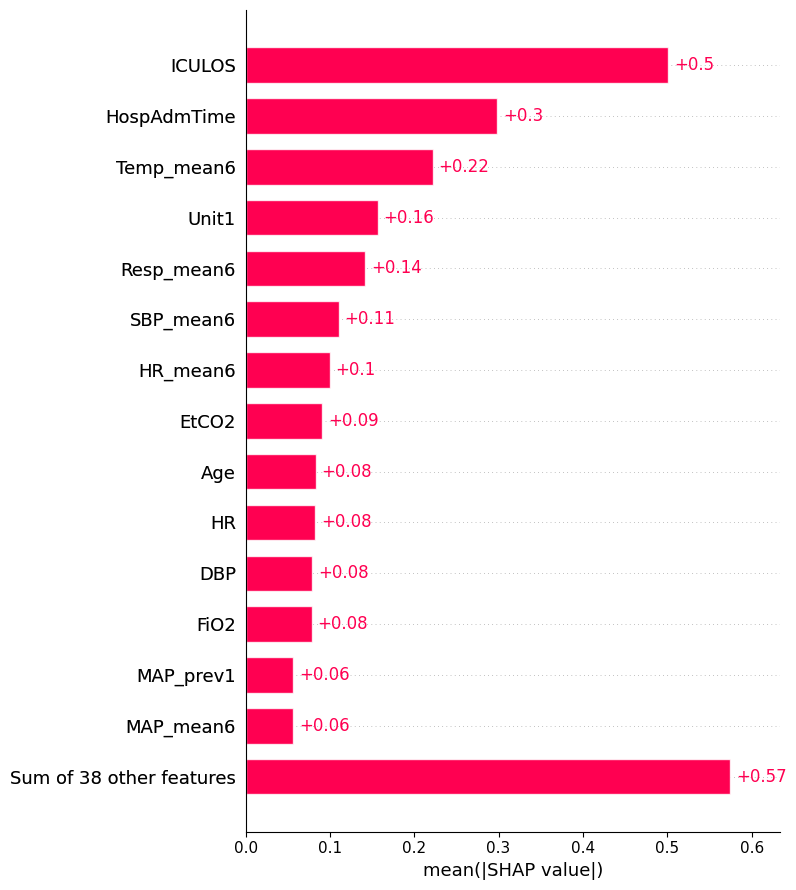

Saved SHAP chart: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/shap_feature_importance.png


In [ ]:
31# Purpose: Explain XGBoost predictions using SHAP feature importance.

import shap
import matplotlib.pyplot as plt
import xgboost as xgb

RESULTS = OUT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

X_test = pd.read_parquet(OUT / "processed" / "test_data" / "X_test.parquet")

sample = pd.read_parquet(sorted(FEATURES.glob("batch_*.parquet"))[0])
FEATURE_COLS = [
    c for c in sample.columns
    if c not in {"PatientID", "SepsisLabel"}
]

X_test = X_test[FEATURE_COLS].sample(
    n=min(500, len(X_test)), random_state=42
)

model = xgb.XGBClassifier()
model.load_model(str(MODEL_DIR / "xgboost_tuned_candidate.json"))

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig(RESULTS / "shap_feature_importance.png",
            dpi=200, bbox_inches="tight")
plt.show()

print("Saved SHAP chart:", RESULTS / "shap_feature_importance.png")

In [ ]:
# Cell: Create the Streamlit dashboard files.
# Purpose: Build a dashboard for model comparison, SHAP explanations, and risk prediction.


from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
WEB = OUT / "website"
WEB.mkdir(parents=True, exist_ok=True)

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import joblib
import json
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import average_precision_score

st.set_page_config(page_title="Sepsis AI", page_icon="🩺", layout="wide")

BASE = Path(__file__).resolve().parent.parent
MODELS = BASE / "models"
RESULTS = BASE / "results"
DATA = BASE / "processed"

st.title("🩺 Early Sepsis Detection")
st.caption("Explainable AI research prototype | PhysioNet 2019")

st.warning(
    "Research prototype only. Not validated for clinical use. "
    "Do not use this dashboard to make patient-care decisions."
)

@st.cache_resource
def load_xgb():
    model = xgb.XGBClassifier()
    model.load_model(str(MODELS / "xgboost_tuned_candidate.json"))
    return model

@st.cache_resource
def load_lstm():
    import tensorflow as tf
    return tf.keras.models.load_model(MODELS / "lstm_sepsis.keras")

@st.cache_data
def load_comparison():
    return pd.read_csv(RESULTS / "final_model_comparison.csv")

tab1, tab2, tab3, tab4 = st.tabs([
    "Overview", "Model Comparison", "Risk Prediction", "Explainability"
])

with tab1:
    st.subheader("Project Overview")
    c1, c2, c3 = st.columns(3)
    c1.metric("Patients processed", "40,336")
    c2.metric("Hourly records", "1.55 million")
    c3.metric("Input features", "52")
    st.write(
        "This project compares XGBoost and LSTM models for predicting "
        "sepsis-labelled hours from ICU observations."
    )
    st.info(
        "The models predict dataset labels, not confirmed clinical diagnoses. "
        "Performance depends on the threshold and evaluation method."
    )

with tab2:
    st.subheader("Held-out Test Results")
    comparison = load_comparison()
    st.dataframe(comparison.round(4), use_container_width=True)
    st.bar_chart(comparison.set_index("Model")[["PR-AUC", "ROC-AUC", "F1"]])
    st.caption(
        "Recall and precision use the listed thresholds. "
        "The tuned XGBoost threshold was selected using validation data."
    )

with tab3:
    st.subheader("Predict from uploaded observations")
    st.write(
        "Upload a CSV containing the model's required feature columns. "
        "For LSTM, provide at least 24 chronological hourly rows for one patient."
    )
    model_choice = st.selectbox("Model", ["Tuned XGBoost", "LSTM"])
    uploaded = st.file_uploader("Upload feature CSV", type=["csv"])

    if uploaded:
        df = pd.read_csv(uploaded)
        features = joblib.load(MODELS / "lstm_features.joblib")
        sample = pd.read_parquet(
            sorted((DATA / "temporal_features").glob("batch_*.parquet"))[0]
        )
        xgb_features = [
            c for c in sample.columns if c not in ["PatientID", "SepsisLabel"]
        ]

        if model_choice == "Tuned XGBoost":
            missing = sorted(set(xgb_features) - set(df.columns))
            if missing:
                st.error(f"Missing required columns: {', '.join(missing)}")
            else:
                model = load_xgb()
                probability = model.predict_proba(df[xgb_features])[:, 1]
                st.dataframe(pd.DataFrame({
                    "Row": np.arange(1, len(probability) + 1),
                    "Predicted probability": probability,
                    "Flag at threshold 0.13": probability >= 0.13
                }))
                st.caption("Threshold 0.13 is a research threshold, not a clinical alarm threshold.")

        else:
            if len(df) < 24:
                st.error("LSTM requires at least 24 chronological hourly rows.")
            elif not set(features).issubset(df.columns):
                st.error("CSV is missing one or more required LSTM features.")
            else:
                imputer = joblib.load(MODELS / "lstm_imputer.joblib")
                scaler = joblib.load(MODELS / "lstm_scaler.joblib")
                X = scaler.transform(imputer.transform(df[features])).astype(np.float32)
                windows = np.lib.stride_tricks.sliding_window_view(
                    X, window_shape=24, axis=0
                ).transpose(0, 2, 1)
                probabilities = load_lstm().predict(windows, verbose=0).ravel()
                st.dataframe(pd.DataFrame({
                    "Ending hour": np.arange(24, len(df) + 1),
                    "Predicted probability": probabilities,
                    "Flag at threshold 0.50": probabilities >= 0.50
                }))

with tab4:
    st.subheader("Global Feature Importance (SHAP)")
    chart = RESULTS / "shap_feature_importance.png"
    if chart.exists():
        st.image(str(chart), caption="Mean absolute SHAP values on a test-record sample")
    else:
        st.info("SHAP chart not found. Generate it from the notebook first.")
    st.caption(
        "SHAP describes model influence, not causation. "
        "Time-related features such as ICULOS may strongly influence predictions."
    )
'''

(WEB / "app.py").write_text(app_code, encoding="utf-8")

(WEB / "requirements.txt").write_text(
    "streamlit\npandas\nnumpy\nxgboost\nshap\njoblib\nscikit-learn\nmatplotlib\ntensorflow\npyarrow\n",
    encoding="utf-8"
)

print("Website created:", WEB / "app.py")
print("Requirements created:", WEB / "requirements.txt")
print("Next: inspect and test the dashboard.")

Website created: /content/drive/MyDrive/Early_Sepsis_AI_Clean/website/app.py
Requirements created: /content/drive/MyDrive/Early_Sepsis_AI_Clean/website/requirements.txt
Next: inspect and test the dashboard.
